## Assignment: $k$ Means Clustering


**Q1.** This is a question about clustering. We want to investigate how adjusting the "noisiness" of the data impacts the quality of the algorithm and the difficulty of picking $k$.

1. Run the code below, which creates four datasets: `df0_125`, `df0_25`, `df0_5`, `df1_0`, and `df2_0`. Each data set is created by increasing the amount of `noise` (standard deviation) around the cluster centers, from `0.125` to `0.25` to `0.5` to `1.0` to `2.0`.

```
import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)
```

2. Make scatterplots of the $(X1,X2)$ points by group for each of the datasets. As the `noise` goes up from 0.125 to 2.0, what happens to the visual distinctness of the clusters?
3. Create a scree plot for each of the datasets. Describe how the level of `noise` affects the scree plot (particularly the presence of a clear "elbow") and your ability to definitively select a $k$. (Pay attention to the vertical axis across plots, or put all the scree curves on a single canvas.)
4. Explain the intuition of the elbow, using this numerical simulation as an example.

**Q2.** This question is a case study on clustering.

1. Load the `SIPRI Military Expenditure Database.csv` file in the `./data` folder. This has data about military spending by country. Filter the rows to select only the year 2020, and drop all rows with missing values. I ended up with 148 countries. Is any further cleaning of the variables required?
2. Max-min normalize `Spending (2020 USD)` and `Spending per Capita`. Use a scree plot to determine the optimal number of clusters for the $k$ means clustering algorithm. Make a scatter plot of `Spending (2020 USD)` and `Spending per Capita`, and hue the dots by their cluster membership. Compute a describe table conditional on cluster membership (i.e. `.groupby(cluster).describe()`). What do you see? Where is the United States? Do you notice any patterns in the cluster membership?
3. Repeat part 2 for `Percent of Government Spending` and `Percent of GDP`. How do your results compare to part 2?
4. Use $k$ means clustering with all four numeric variables: `Spending (2020 USD)`, `Spending per Capita`, `Percent of Government Spending`, and `Percent of GDP`. How do your results compare to the previous two parts? 
5. Did the $k$-MC algorithm find any useful patterns for you in analyzing the spending?

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** BAI,Yongqi

**Date:** 2026/10/14

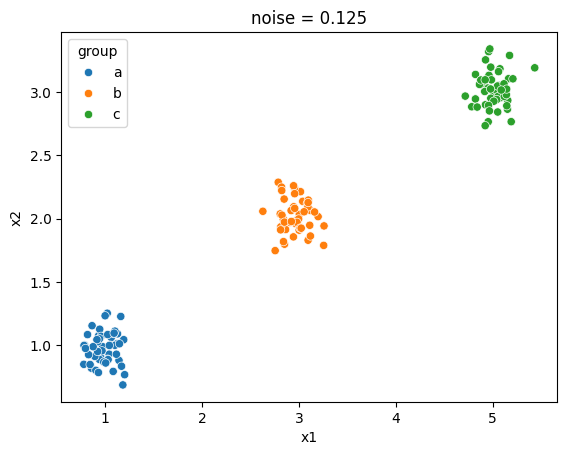

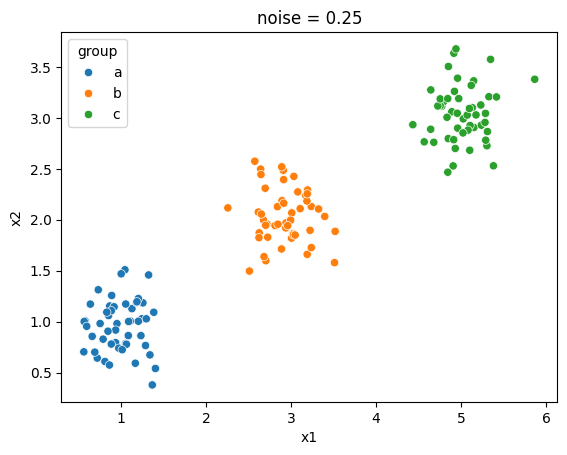

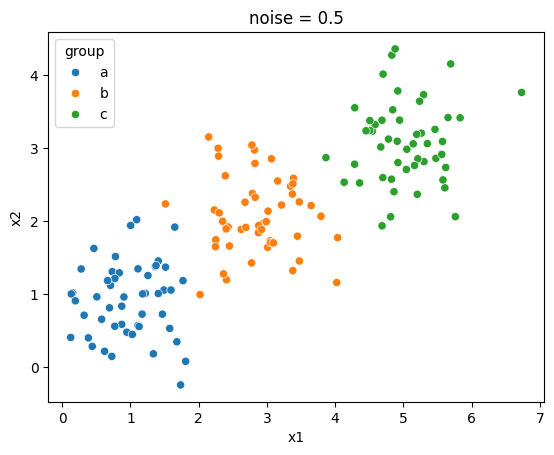

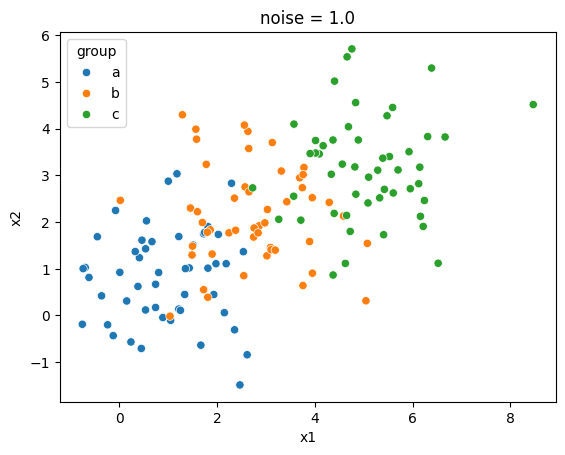

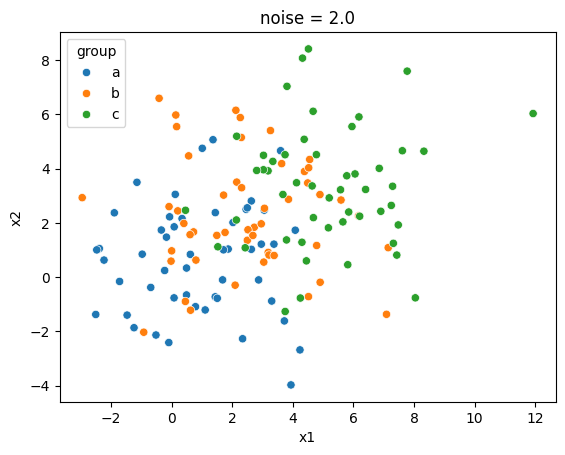

noise 0.125 | SSE for k = 1 to 5: [511.6 128.9   4.9   4.3   3.8]
noise 0.25 | SSE for k = 1 to 5: [533.3 142.7  19.7  17.3  15.2]
noise 0.5 | SSE for k = 1 to 5: [606.6 186.8  77.8  67.2  58.7]
noise 1.0 | SSE for k = 1 to 5: [873.7 361.6 254.9 212.6 175.5]
noise 2.0 | SSE for k = 1 to 5: [1889.2 1071.8  792.3  591.2  501.9]


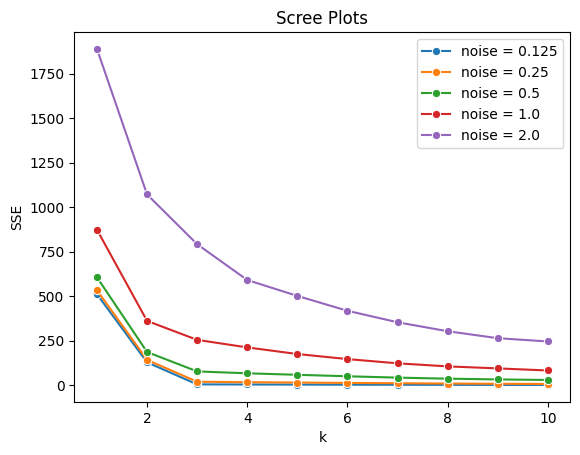

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans

def createData(noise,N=50):
    np.random.seed(100) 
    
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)

# Q1.2
datasets = [df0_125, df0_25, df0_5, df1_0, df2_0]
noises = [0.125, 0.25, 0.5, 1.0, 2.0]
for i in range(len(datasets)):
    sns.scatterplot(data=datasets[i], x='x1', y='x2', hue='group').set_title('noise = ' + str(noises[i]))
    plt.show()

# Q1.3

ks = np.arange(1, 11)
for i in range(len(datasets)):
    X = datasets[i].loc[:, ['x1', 'x2']]
    SSE = [KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0).fit(X).inertia_ for k in ks]
    print('noise', noises[i], '| SSE for k = 1 to 5:', np.round(SSE[:5], 1))
    sns.lineplot(x=ks, y=SSE, marker='o', label='noise = ' + str(noises[i]))
plt.title('Scree Plots')
plt.xlabel('k')
plt.ylabel('SSE')
plt.show()

2. As the noise grows, the groups get harder to tell apart. At 0.125 and 0.25 they are tight and far apart, at 0.5 their edges come close, at 1.0 they overlap, and at 2.0 they merge into one cloud.

3. At low noise the scree plot has a sharp elbow at k = 3, so k = 3 is an easy choice. The elbow fades as the noise grows. At 1.0 the clearest bend moves to k = 2 even though there are three groups, and at 2.0 the curve falls smoothly with no elbow, so no k stands out. SSE is also larger at higher noise, rising from 511.6 to 1889.2 at k = 1.

4. SSE always falls as k grows, so it cannot choose k by itself. While k is below the true number of groups, each new cluster splits apart groups that were lumped together, and SSE falls a lot. Once k passes that number, a new cluster can only split a real group, and SSE barely moves. At noise 0.125, SSE falls from 511.6 to 128.9 to 4.9 as k goes from 1 to 3, then only to 4.3 at k = 4. The elbow is where the big drops turn into small ones. With heavy noise the groups overlap, the two kinds of drops look alike, and the elbow disappears.

(148, 7)
index                               int64
Year                                int64
Country                            object
Spending (2020 USD)               float64
Percent of GDP                    float64
Percent of Government Spending    float64
Spending per Capita               float64
dtype: object


,index,Year,Spending (2020 USD),Percent of GDP,Percent of Government Spending,Spending per Capita
count,148.000000,148.0,148.000000,148.000000,148.000000,148.000000
mean,2831.256757,2020.0,13153.747670,0.019619,0.061510,268.264494
std,1654.299355,0.0,68005.236120,0.015033,0.046207,430.434878
min,32.000000,2020.0,8.622460,0.000054,0.004896,0.580129
25%,1409.000000,2020.0,204.877177,0.010413,0.031352,20.553464
50%,2871.000000,2020.0,959.535443,0.015324,0.047402,81.506703
75%,4222.500000,2020.0,5289.998320,0.024327,0.084681,326.267753
max,5880.000000,2020.0,778397.200000,0.098470,0.303027,2520.398541


count    148.000000
mean       0.349520
std        0.132363
min        0.002851
25%        0.258576
50%        0.338406
75%        0.448049
max        0.746975
Name: implied gov share of GDP, dtype: float64


,index,Year,Country,Spending (2020 USD),Percent of GDP,Percent of Government Spending,Spending per Capita,implied gov share of GDP
5880,5880,2020,Zimbabwe,8.622460,0.000054,0.018941,0.580129,0.002851
406,406,2020,Belarus,707.418033,0.011742,0.303027,74.866974,0.038748


SSE for k = 1 to 6: [5.411 2.435 1.322 0.629 0.415 0.311]


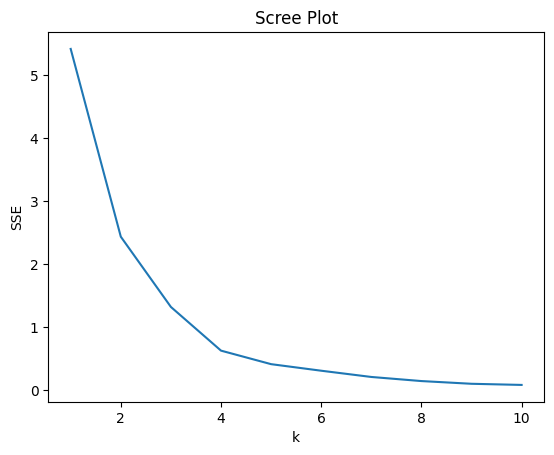

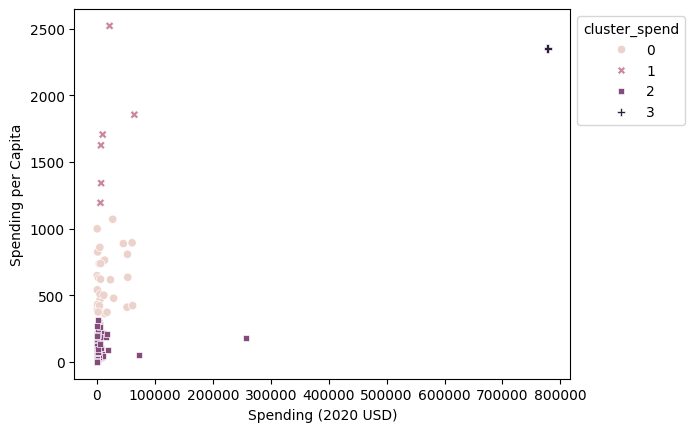

                       Country  Spending (2020 USD)  Spending per Capita  \
1052                     China        257973.429834           179.232355   
5540  United States of America        778397.200000          2351.631858   

      cluster_spend  
1052              2  
5540              3  
cluster 0 ['Australia', 'Austria', 'Bahrain', 'Belgium', 'Brunei', 'Canada', 'Cyprus', 'Denmark', 'Estonia', 'Finland', 'France', 'Germany', 'Greece', 'Italy', 'Japan', 'Korea, South', 'Latvia', 'Lithuania', 'Luxembourg', 'Netherlands', 'New Zealand', 'Poland', 'Portugal', 'Russia', 'Slovakia', 'Spain', 'Sweden', 'Switzerland', 'Taiwan', 'United Kingdom']
cluster 1 ['Israel', 'Kuwait', 'Norway', 'Oman', 'Saudi Arabia', 'Singapore']
cluster 3 ['United States of America']


Spending (2020 USD)                                              \
                            count           mean           std            min   
cluster_spend                                                                   
0                            30.0   17077.591354  20583.053357     405.790494   
1                             6.0   19443.362047  22861.507114    6095.708713   
2                           111.0    4859.185065  25405.739131       8.622460   
3                             1.0  778397.200000           NaN  778397.200000   

                                                                           \
                         25%            50%            75%            max   
cluster_spend                                                               
0                2294.039665    5857.060906   26296.001003   61712.537169   
1                7023.251766    8624.225729   18857.070183   64558.400000   
2                 130.010211     382.464677    2297.032353  257973.429834   
3              778397.200000  778397.200000  778397.200000  778397.200000   

              Spending per Capita                                        \
                            count         mean         std          min   
cluster_spend                                                             
0                            30.0   607.478618  206.928757   362.467076   
1                             6.0  1706.721916  466.375705  1193.598730   
2                           111.0    80.061470   83.501824     0.580129   
3                             1.0  2351.631858         NaN  2351.631858   

                                                                   
                       25%          50%          75%          max  
cluster_spend                                                      
0               422.208252   579.004604   757.328513  1070.623322  
1              1412.083201  1665.447478  1817.219993  2520.398541  
2                14.880549    47.056944   125.387558   314.201312  
3              2351.631858  2351.631858  2351.631858  2351.631858

SSE for k = 1 to 6: [6.961 2.927 1.996 1.477 1.083 0.803]


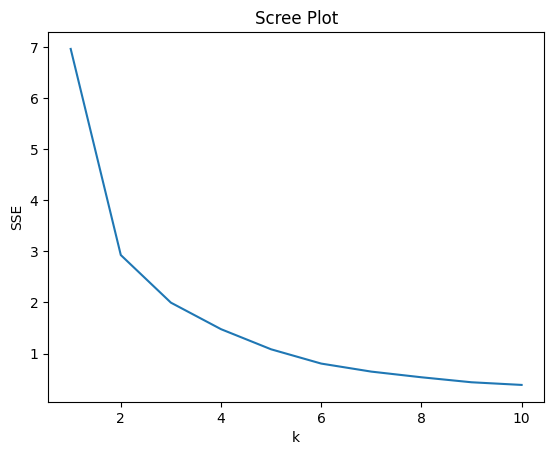

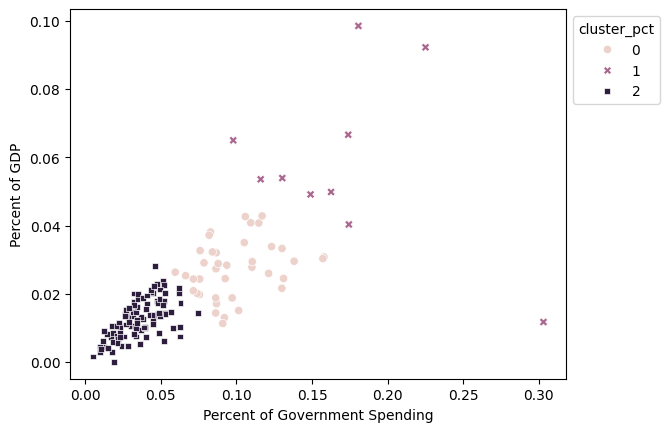

                       Country  Percent of Government Spending  \
1052                     China                        0.047517   
5540  United States of America                        0.081976   

      Percent of GDP  cluster_pct  
1052        0.017988            2  
5540        0.037179            0  
cluster 0 ['Bahrain', 'Bangladesh', 'Botswana', 'Brunei', 'Burkina Faso', 'Burundi', 'Cambodia', 'Central African Republic', 'Chad', 'Chile', 'Colombia', 'Congo, Republic', 'Ecuador', 'Equatorial Guinea', 'Gabon', 'Guinea', 'India', 'Iran', 'Iraq', 'Korea, South', 'Lebanon', 'Mali', 'Mauritania', 'Morocco', 'Myanmar', 'Namibia', 'Niger', 'Russia', 'Singapore', 'South Sudan', 'Sri Lanka', 'Sudan', 'Taiwan', 'Togo', 'Tunisia', 'Turkey', 'Uganda', 'Ukraine', 'United States of America']
cluster 1 ['Algeria', 'Armenia', 'Azerbaijan', 'Belarus', 'Israel', 'Jordan', 'Kuwait', 'Oman', 'Pakistan', 'Saudi Arabia']


Percent of Government Spending                                \
                                     count      mean       std       min   
cluster_pct                                                                
0                                     39.0  0.098683  0.024125  0.059520   
1                                     10.0  0.171289  0.058725  0.097882   
2                                     99.0  0.035777  0.014549  0.004896   

                                                    Percent of GDP            \
                  25%       50%       75%       max          count      mean   
cluster_pct                                                                    
0            0.082430  0.092044  0.112633  0.157918           39.0  0.027412   
1            0.135010  0.168248  0.179081  0.303027           10.0  0.058071   
2            0.025921  0.034261  0.047402  0.074624           99.0  0.012664   

                                                                         
                  std       min       25%       50%       75%       max  
cluster_pct                                                              
0            0.008191  0.011317  0.021254  0.027781  0.032461  0.042810  
1            0.024867  0.011742  0.049297  0.053729  0.066190  0.098470  
2            0.005681  0.000054  0.008393  0.013191  0.016752  0.028132

SSE for k = 1 to 6: [12.372  7.71   5.193  4.207  3.258  2.686]


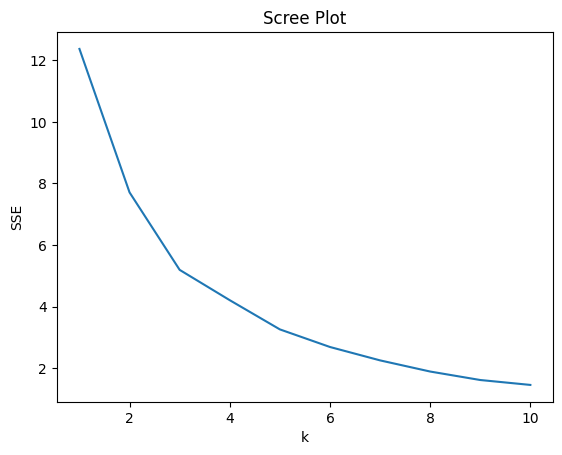

cluster 1 ['Algeria', 'Armenia', 'Azerbaijan', 'Bahrain', 'Belarus', 'Botswana', 'Brunei', 'Burkina Faso', 'Cambodia', 'Chad', 'Colombia', 'Congo, Republic', 'Equatorial Guinea', 'India', 'Iran', 'Iraq', 'Jordan', 'Korea, South', 'Lebanon', 'Mali', 'Mauritania', 'Morocco', 'Myanmar', 'Namibia', 'Pakistan', 'Russia', 'Taiwan', 'Togo', 'Tunisia', 'Uganda', 'Ukraine']
cluster 2 ['Israel', 'Kuwait', 'Oman', 'Saudi Arabia', 'Singapore', 'United States of America']
cluster_pct   0  1   2
cluster_all           
0            12  0  99
1            25  6   0
2             2  4   0


Spending (2020 USD)                                             \
                          count           mean            std          min   
cluster_all                                                                  
0                         111.0    7086.472777   26479.379918     8.622460   
1                          31.0    8786.086602   17901.909108   162.373364   
2                           6.0  147964.582042  309635.189564  6095.708713   

                                                                     \
                     25%           50%           75%            max   
cluster_all                                                           
0             130.010211    567.650747   3910.107493  257973.429834   
1             467.787851   1404.787234   7739.166193   72937.064048   
2            7700.424616  15897.570598  53872.942442  778397.200000   

            Spending per Capita                                        \
                          count         mean         std          min   
cluster_all                                                             
0                         111.0   196.926833  267.788506     0.580129   
1                          31.0   212.689100  257.841988    18.297119   
2                           6.0  1875.150751  489.800206  1193.598730   

                                                                 \
                     25%          50%          75%          max   
cluster_all                                                       
0              14.880549    67.083417   295.296094  1341.058851   
1              46.485917   135.459845   217.333791   998.966186   
2            1645.301864  1780.059564  2227.318999  2520.398541   

            Percent of Government Spending                                \
                                     count      mean       std       min   
cluster_all                                                                
0                                    111.0  0.040350  0.019320  0.004896   
1                                     31.0  0.122985  0.043927  0.076005   
2                                      6.0  0.135351  0.055392  0.081976   

                                                    Percent of GDP            \
                  25%       50%       75%       max          count      mean   
cluster_all                                                                    
0            0.026712  0.037952  0.050505  0.092044          111.0  0.013419   
1            0.093093  0.114776  0.134663  0.303027           31.0  0.033492   
2            0.101034  0.113271  0.164503  0.225050            6.0  0.062634   

                                                                         
                  std       min       25%       50%       75%       max  
cluster_all                                                              
0            0.005996  0.000054  0.008873  0.013589  0.017769  0.028132  
1            0.011449  0.011742  0.027560  0.032024  0.040531  0.066600  
2            0.028275  0.029429  0.041272  0.059257  0.085398  0.098470

In [2]:
pd.set_option('display.max_columns', None)

# Q2.1
df = pd.read_csv('./data/SIPRI Military Expenditure Database.csv')
df = df.loc[df['Year'] == 2020, :]
df = df.dropna(axis=0)
print(df.shape)
print(df.dtypes)
display(df.describe())

# percent of GDP / percent of government spending = government spending as a share of GDP
df['implied gov share of GDP'] = df['Percent of GDP'] / df['Percent of Government Spending']
print(df['implied gov share of GDP'].describe())
display(df.nsmallest(2, 'implied gov share of GDP'))

# Q2.2
features = ['Spending (2020 USD)', 'Spending per Capita']
unscaled = df.loc[:, features]
mins = unscaled.min()
ranges = unscaled.max() - mins
X = (unscaled - mins) / ranges

SSE = [KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0).fit(X).inertia_ for k in ks]
print('SSE for k = 1 to 6:', np.round(SSE[:6], 3))
sns.lineplot(x=ks, y=SSE).set(title='Scree Plot', xlabel='k', ylabel='SSE')
plt.show()

model = KMeans(n_clusters=4, max_iter=300, n_init=10, random_state=0).fit(X)
df['cluster_spend'] = model.labels_
ax = sns.scatterplot(data=df, x='Spending (2020 USD)', y='Spending per Capita', hue='cluster_spend', style='cluster_spend')
sns.move_legend(ax, 'upper left', bbox_to_anchor=(1, 1))
plt.show()

print(df.loc[df['Country'].isin(['United States of America', 'China']), ['Country'] + features + ['cluster_spend']])
for c in range(4):
    members = df.loc[df['cluster_spend'] == c, 'Country']
    if len(members) < 50:
        print('cluster', c, list(members))
display(df.groupby('cluster_spend')[features].describe())

# Q2.3
features = ['Percent of Government Spending', 'Percent of GDP']
unscaled = df.loc[:, features]
mins = unscaled.min()
ranges = unscaled.max() - mins
X = (unscaled - mins) / ranges

SSE = [KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0).fit(X).inertia_ for k in ks]
print('SSE for k = 1 to 6:', np.round(SSE[:6], 3))
sns.lineplot(x=ks, y=SSE).set(title='Scree Plot', xlabel='k', ylabel='SSE')
plt.show()

model = KMeans(n_clusters=3, max_iter=300, n_init=10, random_state=0).fit(X)
df['cluster_pct'] = model.labels_
ax = sns.scatterplot(data=df, x='Percent of Government Spending', y='Percent of GDP', hue='cluster_pct', style='cluster_pct')
sns.move_legend(ax, 'upper left', bbox_to_anchor=(1, 1))
plt.show()

print(df.loc[df['Country'].isin(['United States of America', 'China']), ['Country'] + features + ['cluster_pct']])
for c in range(3):
    members = df.loc[df['cluster_pct'] == c, 'Country']
    if len(members) < 50:
        print('cluster', c, list(members))
display(df.groupby('cluster_pct')[features].describe())

# Q2.4
features = ['Spending (2020 USD)', 'Spending per Capita', 'Percent of Government Spending', 'Percent of GDP']
unscaled = df.loc[:, features]
mins = unscaled.min()
ranges = unscaled.max() - mins
X = (unscaled - mins) / ranges

SSE = [KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0).fit(X).inertia_ for k in ks]
print('SSE for k = 1 to 6:', np.round(SSE[:6], 3))
sns.lineplot(x=ks, y=SSE).set(title='Scree Plot', xlabel='k', ylabel='SSE')
plt.show()

model = KMeans(n_clusters=3, max_iter=300, n_init=10, random_state=0).fit(X)
df['cluster_all'] = model.labels_
for c in range(3):
    members = df.loc[df['cluster_all'] == c, 'Country']
    if len(members) < 50:
        print('cluster', c, list(members))
print(pd.crosstab(df['cluster_all'], df['cluster_pct']))
display(df.groupby('cluster_all')[features].describe())

1. After keeping 2020 and dropping missing values, 148 countries remain. All four variables are already numeric, so no type conversion is needed. Two rows look wrong, though. Percent of GDP divided by percent of government spending gives government spending as a share of GDP, which is 26% to 45% for the middle half of countries but 0.3% for Zimbabwe and 3.9% for Belarus. Belarus's 30% of government spending is probably ten times too high, since 3% would put it in the normal range. I keep both rows to match the 148 countries.

2. The scree plot falls steeply until k = 4 and flattens after, with SSE at 5.41 for k = 1, 0.63 for k = 4 and 0.42 for k = 5, so I use k = 4. The US is a cluster by itself at 778 billion dollars. The other three clusters are levels of spending per person. Israel, Kuwait, Norway, Oman, Saudi Arabia and Singapore have a median of 1,665 dollars per person, a group of 30 mostly European countries has 579, and the other 111 have 47. Total spending only separates the US, because max-min scaling pushes almost every other country near zero on that axis. China spends the second most at 258 billion dollars, but at only 179 dollars per person it lands in the lowest cluster.

3. The elbow is less clear here. SSE is 6.96, 2.93, 2.00 and 1.48 for k = 1 to 4, so the sharpest bend is at k = 2. Since the elbow does not settle it, I choose k by how the clusters will be used and take k = 3, which separates low, middle and high military burden. Ten countries, mostly in the Middle East and the Caucasus, have medians of 16.8% of government spending and 5.4% of GDP, a middle group of 39 has 9.2% and 2.8%, and the other 99 have 3.4% and 1.3%. Unlike part 2, these clusters measure burden rather than size, and the biggest spenders are not the most burdened. The US is no longer alone. At 8.2% of government spending and 3.7% of GDP it sits in the middle group with Russia, India, South Korea and Ukraine, while China and most of Europe are in the lowest group. Belarus is in the top group only because of its doubtful 30%.

4. The elbow is at k = 3, with SSE at 12.37, 7.71, 5.19 and 4.21 for k = 1 to 4. The top cluster is Israel, Kuwait, Oman, Saudi Arabia, Singapore and the US, which spend a lot both per person and as a share of their economy. A middle group of 31, including India, Pakistan, Russia and Ukraine, carries a heavy burden but spends much less per person, with medians of 11.5% of government spending and 135 dollars per person. The other 111 spend little by both measures. The result is closer to part 3, since all 99 countries in the lowest group of part 3 are in the lowest group here. Compared with part 2, the US joins the high per-person group and Norway leaves it because its burden is low.

5. Yes, at a rough level. The clusters separate countries by spending per person, pick out countries where the military takes a large share of the budget, and with all four variables find a small group of rich countries that spend heavily on the military. The limits are clear too. Total spending is so skewed that the US alone sets that axis, which is why China lands in the lowest cluster in part 2. The elbow for the percent variables is soft, so k there is partly a judgment call, and Belarus's doubtful value sets the scale of one axis. The clusters are good for exploring the data but not for firm conclusions.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** c00ce58df4591c4276d9b2e40f7e53ca8d75516b
- **AI tool and model used:** Claude

### *Prompts used

1. Shared my Phase 1 commit (c00ce58) with Claude and asked it to review the Phase 1 notebook and suggest revisions.
2. Are there any obvious flaws or errors?

### *AI-proposed changes


1. Q1.2: Draw the five scatterplots side by side with shared axes. Each panel now rescales to its own data, which hides how far the points spread as the noise grows.
2. Q1: Measure the algorithm's quality directly. Fit k = 3 at each noise level and compare the clusters with the true groups; the question asks how noise affects the quality of the algorithm, and the plots alone do not measure it.
3. Q1.3: Add a scree plot of SSE as a share of SSE at k = 1, so the five curves share one vertical scale, and revise the high-noise description. At 1.0 and 2.0 the bend at k = 2 comes from the whole cloud being long (the three centers lie on a line), not from two real groups, and the 2.0 curve does not fall smoothly: it loses 43% of its SSE at k = 2.
4. Q1.4: Make the intuition quantitative with the known groups. Because createData resets the seed, every dataset is the same draws stretched by the noise, so the SSE of the true groups grows exactly with noise² (4.9 at 0.125, 1257.8 at 2.0), while the spread of the group centers adds about 500 to 630. The elbow is sharp while the second part dominates and fades as the first catches up.
5. Q2.1: Check the two flagged rows against each country's other years, state the units, and drop the index column. Belarus is at 29% to 33% of government spending in every year from 2012 to 2021, so the error is systematic rather than a 2020 typo. Zimbabwe's 2020 values are all 1% to 2% of its 2019 values, and it is the only country with a share of government spending above 100% (12 years between 2005 and 2019). Spending is in millions of 2020 USD (778,397 for the US is $778 billion), the percent columns are fractions, and index only repeats the row number.
6. Q2.1 and Q2.5: Test whether the two doubtful rows change the results. Re-run parts 3 and 4 with Belarus's share divided by 10 and with Zimbabwe dropped, using a larger n_init so that a worse local optimum does not distort the comparison, and report which countries move.
7. Q2.2: Use log-scaled axes and a categorical palette for the scatterplot. 138 of the 148 countries spend less than 5% of the US total, so on linear axes they sit in a thin strip at the left edge, and clusters 0 and 1 get nearly the same color. The clustering itself does not change.
8. Q2.2: Say that the scree curve also bends at k = 2, and justify k = 4 by what it adds: with k = 3 the six highest per-capita spenders are merged with 15 countries from the 30-country group.
9. Q2.2 and Q2.5: Log-transform total spending before max-min scaling, so that total spending separates countries other than the US.
10. Code: Put the repeated scale, scree, fit and describe steps into one helper function, and add point markers to the scree plots.
11. Small fixes: in Q1.4 say SSE "generally" falls rather than "always", since k-means is a local search and can miss the lowest SSE; and title each Q2 scree plot with the variables it uses.
12. Q1.2: The k-means clusters already have lower SSE than the true groups at noise 0.5 (77.8 against 78.6), not only at 1.0 and 2.0; say "from 0.5 on".
13. Q2.1: Print Belarus's whole series (2001 to 2021) instead of 2012 to 2021, so the claim that the problem runs through its whole series is backed by the output.
14. Q2.1: Display Zimbabwe's 2019 and 2020 rows and the percent of GDP implied by its 2020 share, so the corrected Zimbabwe reasoning can be checked in the output.
15. Q2.2: Write "the six highest per-capita spenders other than the US", since the US (2,352 dollars per person) ranks second, behind Israel.
16. Q2.3: "The biggest spenders are not the most burdened" is too broad, since Saudi Arabia, the fourth biggest spender, is in the top group. Say that of the five biggest spenders only Saudi Arabia is in the top group, and print the five.
17. Q2.4: By the measure used in Q2.2 the larger bend is at k = 2 (SSE falls by 4.66, 2.52, 0.99 and 0.95), so say the curve bends at k = 2 and k = 3 and justify k = 3 by use. Say the middle group spends less per person "than the top cluster", since its median (135 dollars) is above the lowest group's (67). Print the top six and the lowest group's high spenders so the corrected descriptions can be checked.
18. Q2.5: "A small group of rich countries that spend heavily on the military" no longer fits Q2.4: what the top six share is high spending per person, and income is not in the data. Say "a small group with high spending per person".

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept | Each Phase 1 panel rescales to its own data, which hides how much the points spread. On shared axes the 0.125 groups are three small, tight clusters while the 2.0 points fill the frame. Verified by comparing the old and new figures. |
| 2 | Accept | The question asks how noise affects the quality of the algorithm, which Phase 1 did not measure. Matched to the true groups, the k = 3 clusters are 100%, 100%, 98.7%, 81.3% and 58.0% correct. From noise 0.5 on, the k-means clusters have lower SSE than the true groups (77.8 vs 78.6, 254.9 vs 314.4, 792.3 vs 1257.8), so lower SSE stops meaning closer to the truth. Verified with crosstabs of cluster against group. |
| 3 | Accept | On the raw scale the 0.125 and 0.25 curves overlap near zero and the 2.0 curve sets the axis. As a share of SSE at k = 1, the SSE left at k = 3 is 1%, 4%, 13%, 29% and 42%. To test the k = 2 explanation, a single Gaussian cloud with the same mean and covariance as the noise 2.0 data, with no groups at all, keeps about 0.57 and 0.42 of its SSE at k = 2 and 3, the same as the real data. The Phase 1 phrase "falls smoothly" was inaccurate, since SSE drops 43% at k = 2. |
| 4 | Accept | Verified that (x minus its center) divided by the noise is identical across the five datasets (`np.allclose` is True). The SSE of the true groups is 4.9, 19.7, 78.6, 314.4 and 1257.8, exactly 314.4 × noise², while SSE at k = 1 minus that part stays between 507 and 631. This puts numbers on the Phase 1 explanation. |
| 5 | Modify | Kept the history check, the units and dropping index, but corrected the Zimbabwe reasoning. "All four 2020 values are 1% to 2% of 2019" suggests that the 2020 share of government spending is wrong too, but that ratio is low because the 2019 share (176%) is itself impossible. The 2020 share (1.9%) is the one plausible value: with a typical government share it implies 0.5% to 0.8% of GDP, close to the 2019 value of 0.53%. Also checked: US spending divided by its per-capita value gives 331, which matches 331 million people only if spending is in millions, and the index column equals the row number. |
| 6 | Accept | The main analysis keeps all 148 countries to match the assignment, and the re-runs are reported as a check. Dropping Zimbabwe changes nothing in parts 2 and 3 and moves only Equatorial Guinea in part 4. Dividing Belarus's share by 10 leaves part 2 unchanged, moves only Belarus out of the top group in part 3 (Angola and South Sudan also trade places), and moves 7 countries in part 4, because the maximum share falls from 0.303 to 0.225 and the max-min scaling changes. With n_init = 10 the corrected part 3 ends in a worse solution (SSE 2.067 vs 2.042), so the re-runs use n_init = 100; the Phase 1 solutions already match the n_init = 100 SSE (1.996 and 5.193). |
| 7 | Accept | 138 of the 148 countries spend less than 5% of the US total, so on linear axes they form a thin strip. On log axes the clusters other than the US appear as bands of spending per person (up to 314, 362 to 1,071, and 1,194 and above), which matches the describe table. The labels come from the same fit, so the clustering is unchanged. |
| 8 | Accept | SSE drops by 2.98, 1.11, 0.69 and 0.21 from k = 1 to 5, so the largest bend is at k = 2 and a second one at k = 4. A crosstab of the k = 3 and k = 4 labels shows that k = 3 merges the six highest per-capita spenders other than the US with 15 of the 30 mostly European countries; k = 4 keeps them apart, which is the reason for k = 4. |
| 9 | Modify | The question asks to max-min normalize the raw variables, so the analysis stays as it is. A quick test with log spending and k = 4 (not kept in the solution) put the US with Israel, Kuwait, Norway, Oman, Saudi Arabia and Singapore and split the other countries into small, medium and large spenders, so Q2.5 mentions it as a way around the skew. |
| 10 | Accept | One function now runs parts 2 to 4, replacing three copies of the same code. Verified that it reproduces every Phase 1 SSE value and cluster size. |
| 11 | Accept | The lecture slides say SSE "generally" falls as k grows and that Lloyd's algorithm "may not find the global minimum", so "always" was too strong. Titles naming the variables make the three Q2 scree plots easy to tell apart. |
| 12 | Accept | Checked in the output: at 0.5 the k-means SSE is 77.8 against 78.6 for the true groups, and accuracy is already 98.7% rather than 100%. |
| 13 | Accept | The output now covers all of Belarus's years in the file, 2001 to 2021, and its share is between 23.4% and 35.0% in every one of them. |
| 14 | Accept | The output now shows Zimbabwe's 2019 share of 1.761 (176%) next to its 2020 values, and the 2020 share times the middle half of government shares gives 0.49% to 0.849% of GDP, which supports the corrected Q2.1 text. |
| 15 | Accept | Checked: per person, Israel (2,520) is first and the US (2,352) second, followed by Saudi Arabia, Singapore, Kuwait, Norway and Oman (1,194); the US is a cluster by itself, so the merged six are the top six other than the US. |
| 16 | Accept | Checked in the output: the five biggest spenders are the US, China, India, Saudi Arabia and Russia; in part 3 only Saudi Arabia is in the top group, China is in the lowest, and the other three are in the middle. |
| 17 | Accept | Checked in the output: the drops are 4.66, 2.52, 0.99 and 0.95, so the k = 2 bend is the larger one, and k = 3 is kept because it matches part 3 and keeps the top six apart. The middle group's median spending per person is 135 dollars against 67 for the lowest group. The new output lists the top six with their shares of GDP and shows 26 countries in the lowest group at 362 to 1,341 dollars per person: Norway and 25 from part 2's 30-country group. |
| 18 | Accept | The top six share high spending per person (1,194 to 2,520 dollars) but not a high share of GDP (Singapore 2.9%, the US 3.7%), and the data have no income variable, so "rich countries that spend heavily on the military" was not supported. |

Changes not proposed by the AI: I rewrote two passages myself. In Q2.4, two Phase 1 claims that the AI had not flagged were contradicted by the describe table: the top six do not all spend a high share of GDP, and 26 of the lowest 111 spend 362 to 1,341 dollars per person. In Q2.1, the AI's Phase 2 text blamed Zimbabwe's numbers on a currency conversion problem, which cannot explain a share of government spending above 100%.

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

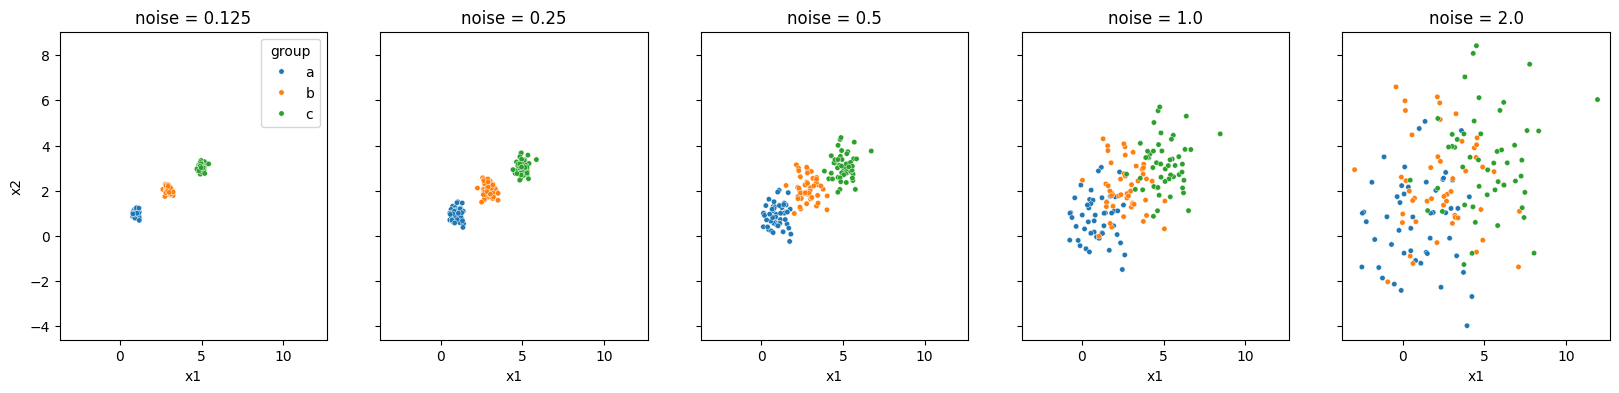

same draws in every dataset: True


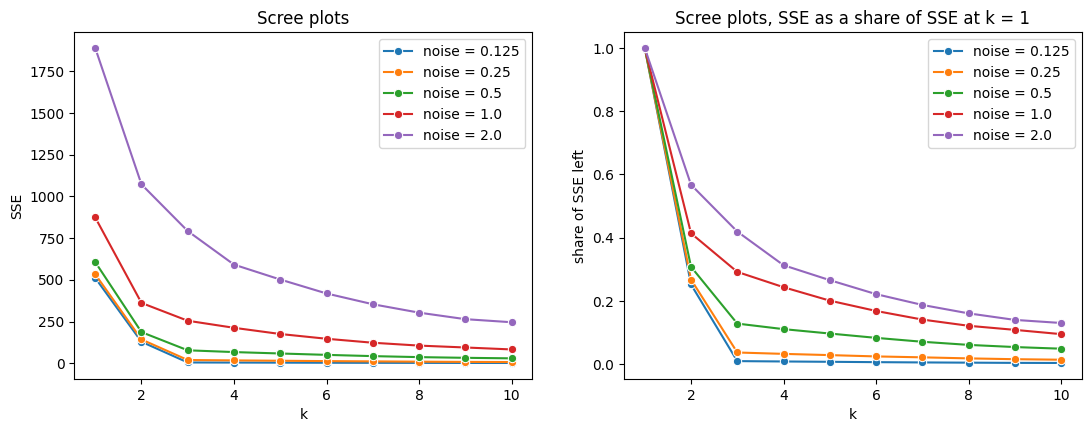

SSE for k = 1 to 5:


,1,2,3,4,5
noise,,,,,
0.125,511.6,128.9,4.9,4.3,3.8
0.250,533.3,142.7,19.7,17.3,15.2
0.500,606.6,186.8,77.8,67.2,58.7
1.000,873.7,361.6,254.9,212.6,175.5
2.000,1889.2,1071.8,792.3,591.2,501.9


Share of SSE left:


,2,3,4,5
noise,,,,
0.125,0.252,0.010,0.008,0.007
0.250,0.268,0.037,0.033,0.029
0.500,0.308,0.128,0.111,0.097
1.000,0.414,0.292,0.243,0.201
2.000,0.567,0.419,0.313,0.266


noise 1.0: one Gaussian cloud keeps 0.465 at k = 2 and 0.327 at k = 3 (data: 0.414 and 0.292)
noise 2.0: one Gaussian cloud keeps 0.573 at k = 2 and 0.416 at k = 3 (data: 0.567 and 0.419)


cluster       0   1   2
noise group            
0.125 a       0  50   0
      b      50   0   0
      c       0   0  50
0.250 a       0  50   0
      b      50   0   0
      c       0   0  50
0.500 a       0  50   0
      b      48   2   0
      c       0   0  50
1.000 a       0  40  10
      b       7   6  37
      c      45   0   5
2.000 a       1  42   7
      b       8  24  18
      c      27   6  17

,k-means SSE (k = 3),SSE of true groups,SSE at k = 1 minus true groups,k = 3 accuracy
noise,,,,
0.125,4.913,4.913,506.699,1.000
0.250,19.653,19.653,513.599,1.000
0.500,77.817,78.611,528.006,0.987
1.000,254.914,314.446,559.245,0.813
2.000,792.272,1257.784,631.418,0.580


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans

def createData(noise,N=50):
    np.random.seed(100)

    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])

    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)

datasets = [df0_125, df0_25, df0_5, df1_0, df2_0]
noises = [0.125, 0.25, 0.5, 1.0, 2.0]

# Q1.2: all five datasets on shared axes
fig, axes = plt.subplots(1, 5, figsize=(20, 4), sharex=True, sharey=True)
for i in range(len(datasets)):
    sns.scatterplot(data=datasets[i], x='x1', y='x2', hue='group', s=15, ax=axes[i], legend='auto' if i == 0 else False)
    axes[i].set_title('noise = ' + str(noises[i]))
plt.show()

# every dataset is the same random draws stretched by the noise
def standardized(df, noise):
    cx = df['group'].map({'a': 1, 'b': 3, 'c': 5})
    cy = df['group'].map({'a': 1, 'b': 2, 'c': 3})
    return np.c_[(df['x1'] - cx) / noise, (df['x2'] - cy) / noise]
print('same draws in every dataset:', all(np.allclose(standardized(datasets[i], noises[i]), standardized(df0_125, 0.125)) for i in range(5)))

# Q1.3: scree plots, raw and as a share of SSE at k = 1
ks = np.arange(1, 11)
SSEs = []
for i in range(len(datasets)):
    X = datasets[i].loc[:, ['x1', 'x2']]
    SSEs.append([KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0).fit(X).inertia_ for k in ks])
sse_table = pd.DataFrame(SSEs, index=pd.Index(noises, name='noise'), columns=ks)
share_table = sse_table.div(sse_table[1], axis=0)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for i in range(len(datasets)):
    sns.lineplot(x=ks, y=sse_table.iloc[i].values, marker='o', label='noise = ' + str(noises[i]), ax=axes[0])
    sns.lineplot(x=ks, y=share_table.iloc[i].values, marker='o', label='noise = ' + str(noises[i]), ax=axes[1])
axes[0].set(title='Scree plots', xlabel='k', ylabel='SSE')
axes[1].set(title='Scree plots, SSE as a share of SSE at k = 1', xlabel='k', ylabel='share of SSE left')
plt.show()
print('SSE for k = 1 to 5:'); display(sse_table.loc[:, 1:5].round(1))
print('Share of SSE left:'); display(share_table.loc[:, 2:5].round(3))

# one Gaussian cloud with the same mean and covariance as the data, no groups
rng = np.random.default_rng(0)
for i in [3, 4]:
    X = datasets[i].loc[:, ['x1', 'x2']].values
    shares = []
    for rep in range(20):
        Y = rng.multivariate_normal(X.mean(axis=0), np.cov(X.T), size=len(X))
        sse = [KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0).fit(Y).inertia_ for k in [1, 2, 3]]
        shares.append([sse[1] / sse[0], sse[2] / sse[0]])
    shares = np.mean(shares, axis=0)
    print('noise %s: one Gaussian cloud keeps %.3f at k = 2 and %.3f at k = 3 (data: %.3f and %.3f)'
          % (noises[i], shares[0], shares[1], share_table.loc[noises[i], 2], share_table.loc[noises[i], 3]))

# quality of the algorithm: k = 3 clusters against the true groups
rows, tables = [], []
for i in range(len(datasets)):
    group = datasets[i]['group'].values
    X = datasets[i].loc[:, ['x1', 'x2']].values
    labels = KMeans(n_clusters=3, max_iter=300, n_init=10, random_state=0).fit(X).labels_
    ct = pd.crosstab(group, labels, rownames=['group'], colnames=['cluster'])
    tables.append(ct)
    true_sse = sum(((X[group == g] - X[group == g].mean(axis=0)) ** 2).sum() for g in ['a', 'b', 'c'])
    rows.append({'k-means SSE (k = 3)': SSEs[i][2],
                 'SSE of true groups': true_sse,
                 'SSE at k = 1 minus true groups': SSEs[i][0] - true_sse,
                 'k = 3 accuracy': ct.max(axis=0).sum() / len(group)})
display(pd.concat(tables, keys=noises, names=['noise', 'group']))
display(pd.DataFrame(rows, index=pd.Index(noises, name='noise')).round(3))


**Q1.2.** As the noise grows, the groups get harder to tell apart. On shared axes, at 0.125 and 0.25 they are three tight clusters far apart, at 0.5 their edges come close, at 1.0 they overlap, and at 2.0 they merge into one cloud that fills the frame. The quality of the algorithm drops with them. Matching each k = 3 cluster to the group it mostly contains, k-means puts 100% of the points in the right group at 0.125 and 0.25, 98.7% at 0.5, 81.3% at 1.0 and 58.0% at 2.0. From noise 0.5 on, its clusters have lower SSE than the true groups (77.8 against 78.6 at 0.5, 254.9 against 314.4 at 1.0, and 792.3 against 1257.8 at 2.0), so the split with the lowest SSE is no longer the real one, and the gap grows with the noise.

**Q1.3.** At low noise the scree plot has a sharp elbow at k = 3, so k = 3 is an easy choice: at 0.125 only 1% of the SSE at k = 1 is left at k = 3. The elbow fades as the noise grows, and the share left at k = 3 rises to 4%, 13%, 29% and 42% (right panel). At 1.0 the clearest bend moves to k = 2 even though there are three groups. At 2.0 the curve still drops 43% at k = 2 and then declines gradually with no clear elbow. The bend at k = 2 does not mean two groups. Once the groups overlap, the three centers on a line from (1, 1) to (5, 3) make one long cloud, and cutting a long cloud in two removes a lot of SSE. A single Gaussian cloud with the same mean and covariance as the 2.0 data, with no groups at all, keeps on average 0.57 and 0.42 of its SSE at k = 2 and 3, the same as the data. At 1.0 it keeps 0.47 at k = 2 against 0.41 in the data. So at high noise the scree plot carries almost no sign of the three groups, and no k can be picked with confidence. SSE is also larger at higher noise, rising from 511.6 to 1889.2 at k = 1 (left panel).

**Q1.4.** SSE generally falls as k grows, so it cannot choose k by itself. While k is below the true number of groups, each new cluster splits apart groups that were lumped together, and SSE falls a lot. Once k passes that number, a new cluster can only split a real group, and SSE barely moves. At noise 0.125, SSE falls from 511.6 to 128.9 to 4.9 as k goes from 1 to 3, then only to 4.3 at k = 4. The elbow is where the big drops turn into small ones.

The simulation puts numbers on this. Because `createData` resets the seed, the five datasets are the same draws stretched by the noise (the `np.allclose` check prints True). So the SSE of the true groups, which is pure noise, is exactly 314.4 × noise²: 4.9, 19.7, 78.6, 314.4 and 1257.8. The rest of the SSE at k = 1 comes from the spread of the group centers and stays between 507 and 631. The big drops up to k = 3 remove the center part, and the small drops after it only chip at the noise part. While the center part is much larger, up to noise 0.5, the elbow at k = 3 is sharp. At 1.0 the noise part is already more than half the center part, and at 2.0 it is twice as large, so the two kinds of drops look alike and the elbow disappears.

index equals the row number: True
(148, 6)
Year                                int64
Country                            object
Spending (2020 USD)               float64
Percent of GDP                    float64
Percent of Government Spending    float64
Spending per Capita               float64
dtype: object


,Spending (2020 USD),Spending per Capita,Percent of Government Spending,Percent of GDP
count,148.000000,148.000000,148.000000,148.000000
mean,13153.747670,268.264494,0.061510,0.019619
std,68005.236120,430.434878,0.046207,0.015033
min,8.622460,0.580129,0.004896,0.000054
25%,204.877177,20.553464,0.031352,0.010413
50%,959.535443,81.506703,0.047402,0.015324
75%,5289.998320,326.267753,0.084681,0.024327
max,778397.200000,2520.398541,0.303027,0.098470


US spending / US spending per capita: 331.0
count    148.000000
mean       0.349520
std        0.132363
min        0.002851
25%        0.258576
50%        0.338406
75%        0.448049
max        0.746975
Name: implied gov share of GDP, dtype: float64


,Year,Country,Spending (2020 USD),Percent of GDP,Percent of Government Spending,Spending per Capita,implied gov share of GDP
147,2020,Zimbabwe,8.622460,0.000054,0.018941,0.580129,0.002851
11,2020,Belarus,707.418033,0.011742,0.303027,74.866974,0.038748


Belarus, % of government spending 2001-2021: 0.234 to 0.350


,Spending (2020 USD),Spending per Capita,Percent of Government Spending,Percent of GDP
Year,,,,
2019,796.573534,37.346466,1.761478,0.005348
2020,8.622460,0.580129,0.018941,0.000054


Zimbabwe, 2020 value / 2019 value:
Spending (2020 USD)               0.011
Spending per Capita               0.016
Percent of Government Spending    0.011
Percent of GDP                    0.010
dtype: float64
rows above 100% of government spending: 12 | countries: ['Zimbabwe'] | years: 2005 to 2019
Zimbabwe 2020 share x middle half of government shares of GDP (% of GDP): [0.49, 0.849]
SSE for k = 1 to 6: [5.411 2.435 1.322 0.629 0.415 0.311] | drops: [2.98 1.11 0.69 0.21 0.1 ]


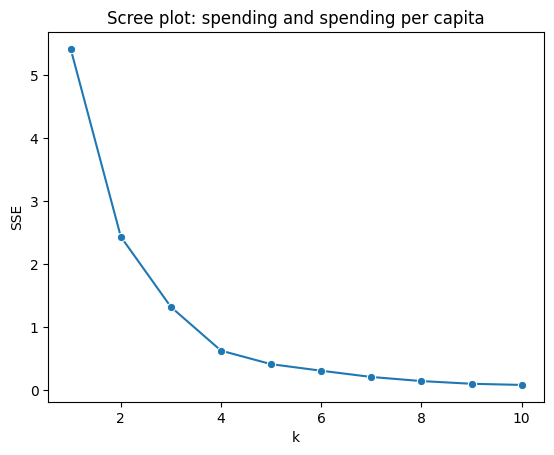

cluster 0 ['Australia', 'Austria', 'Bahrain', 'Belgium', 'Brunei', 'Canada', 'Cyprus', 'Denmark', 'Estonia', 'Finland', 'France', 'Germany', 'Greece', 'Italy', 'Japan', 'Korea, South', 'Latvia', 'Lithuania', 'Luxembourg', 'Netherlands', 'New Zealand', 'Poland', 'Portugal', 'Russia', 'Slovakia', 'Spain', 'Sweden', 'Switzerland', 'Taiwan', 'United Kingdom']
cluster 1 ['Israel', 'Kuwait', 'Norway', 'Oman', 'Saudi Arabia', 'Singapore']
cluster 3 ['United States of America']


Spending (2020 USD)                                              \
                      count           mean           std            min   
cluster                                                                   
0                      30.0   17077.591354  20583.053357     405.790494   
1                       6.0   19443.362047  22861.507114    6095.708713   
2                     111.0    4859.185065  25405.739131       8.622460   
3                       1.0  778397.200000           NaN  778397.200000   

                                                                     \
                   25%            50%            75%            max   
cluster                                                               
0          2294.039665    5857.060906   26296.001003   61712.537169   
1          7023.251766    8624.225729   18857.070183   64558.400000   
2           130.010211     382.464677    2297.032353  257973.429834   
3        778397.200000  778397.200000  778397.200000  778397.200000   

        Spending per Capita                                        \
                      count         mean         std          min   
cluster                                                             
0                      30.0   607.478618  206.928757   362.467076   
1                       6.0  1706.721916  466.375705  1193.598730   
2                     111.0    80.061470   83.501824     0.580129   
3                       1.0  2351.631858         NaN  2351.631858   

                                                             
                 25%          50%          75%          max  
cluster                                                      
0         422.208252   579.004604   757.328513  1070.623322  
1        1412.083201  1665.447478  1817.219993  2520.398541  
2          14.880549    47.056944   125.387558   314.201312  
3        2351.631858  2351.631858  2351.631858  2351.631858

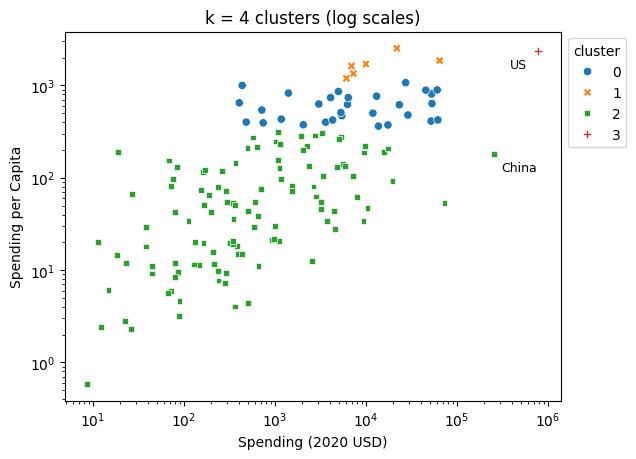

                      Country  Spending (2020 USD)  Spending per Capita  \
30                      China        257973.429834           179.232355   
144  United States of America        778397.200000          2351.631858   

     cluster_spend  
30               2  
144              3  
countries spending less than 5% of the US total: 138 of 148
k = 4   0  1    2  3
k = 3               
0      15  6    0  0
1      15  0  111  0
2       0  0    0  1
SSE for k = 1 to 6: [6.961 2.927 1.996 1.477 1.083 0.803] | drops: [4.03 0.93 0.52 0.39 0.28]


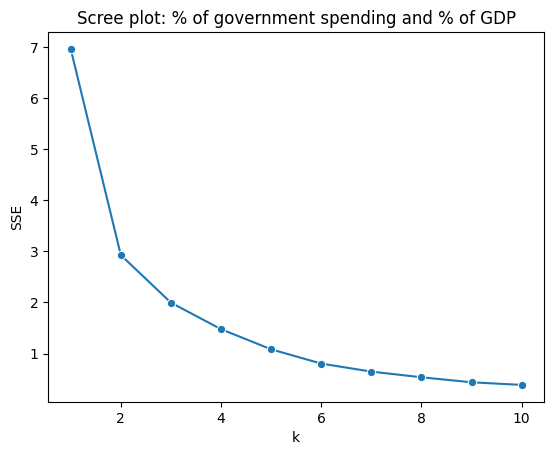

cluster 0 ['Bahrain', 'Bangladesh', 'Botswana', 'Brunei', 'Burkina Faso', 'Burundi', 'Cambodia', 'Central African Republic', 'Chad', 'Chile', 'Colombia', 'Congo, Republic', 'Ecuador', 'Equatorial Guinea', 'Gabon', 'Guinea', 'India', 'Iran', 'Iraq', 'Korea, South', 'Lebanon', 'Mali', 'Mauritania', 'Morocco', 'Myanmar', 'Namibia', 'Niger', 'Russia', 'Singapore', 'South Sudan', 'Sri Lanka', 'Sudan', 'Taiwan', 'Togo', 'Tunisia', 'Turkey', 'Uganda', 'Ukraine', 'United States of America']
cluster 1 ['Algeria', 'Armenia', 'Azerbaijan', 'Belarus', 'Israel', 'Jordan', 'Kuwait', 'Oman', 'Pakistan', 'Saudi Arabia']


Percent of Government Spending                                \
                                 count      mean       std       min   
cluster                                                                
0                                 39.0  0.098683  0.024125  0.059520   
1                                 10.0  0.171289  0.058725  0.097882   
2                                 99.0  0.035777  0.014549  0.004896   

                                                Percent of GDP            \
              25%       50%       75%       max          count      mean   
cluster                                                                    
0        0.082430  0.092044  0.112633  0.157918           39.0  0.027412   
1        0.135010  0.168248  0.179081  0.303027           10.0  0.058071   
2        0.025921  0.034261  0.047402  0.074624           99.0  0.012664   

                                                                     
              std       min       25%       50%       75%       max  
cluster                                                              
0        0.008191  0.011317  0.021254  0.027781  0.032461  0.042810  
1        0.024867  0.011742  0.049297  0.053729  0.066190  0.098470  
2        0.005681  0.000054  0.008393  0.013191  0.016752  0.028132

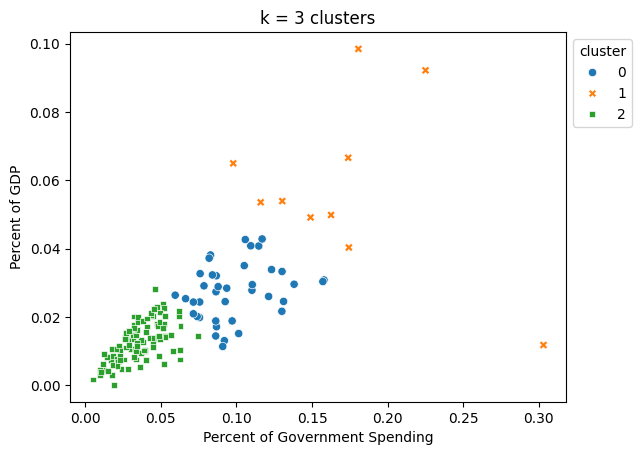

                      Country  Percent of Government Spending  Percent of GDP  \
30                      China                        0.047517        0.017988   
144  United States of America                        0.081976        0.037179   

     cluster_pct  
30             2  
144            0  
                      Country  Spending (2020 USD)  cluster_pct
144  United States of America        778397.200000            0
30                      China        257973.429834            2
61                      India         72937.064048            0
117              Saudi Arabia         64558.400000            1
115                    Russia         61712.537169            0
SSE for k = 1 to 6: [12.372  7.71   5.193  4.207  3.258  2.686] | drops: [4.66 2.52 0.99 0.95 0.57]


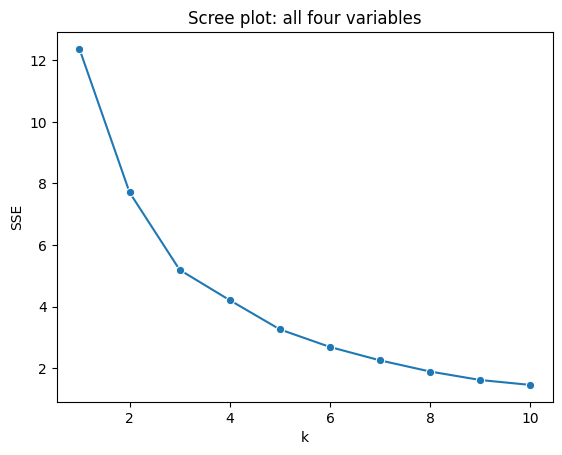

cluster 1 ['Algeria', 'Armenia', 'Azerbaijan', 'Bahrain', 'Belarus', 'Botswana', 'Brunei', 'Burkina Faso', 'Cambodia', 'Chad', 'Colombia', 'Congo, Republic', 'Equatorial Guinea', 'India', 'Iran', 'Iraq', 'Jordan', 'Korea, South', 'Lebanon', 'Mali', 'Mauritania', 'Morocco', 'Myanmar', 'Namibia', 'Pakistan', 'Russia', 'Taiwan', 'Togo', 'Tunisia', 'Uganda', 'Ukraine']
cluster 2 ['Israel', 'Kuwait', 'Oman', 'Saudi Arabia', 'Singapore', 'United States of America']


Spending (2020 USD)                                             \
                      count           mean            std          min   
cluster                                                                  
0                     111.0    7086.472777   26479.379918     8.622460   
1                      31.0    8786.086602   17901.909108   162.373364   
2                       6.0  147964.582042  309635.189564  6095.708713   

                                                                 \
                 25%           50%           75%            max   
cluster                                                           
0         130.010211    567.650747   3910.107493  257973.429834   
1         467.787851   1404.787234   7739.166193   72937.064048   
2        7700.424616  15897.570598  53872.942442  778397.200000   

        Spending per Capita                                        \
                      count         mean         std          min   
cluster                                                             
0                     111.0   196.926833  267.788506     0.580129   
1                      31.0   212.689100  257.841988    18.297119   
2                       6.0  1875.150751  489.800206  1193.598730   

                                                             \
                 25%          50%          75%          max   
cluster                                                       
0          14.880549    67.083417   295.296094  1341.058851   
1          46.485917   135.459845   217.333791   998.966186   
2        1645.301864  1780.059564  2227.318999  2520.398541   

        Percent of Government Spending                                \
                                 count      mean       std       min   
cluster                                                                
0                                111.0  0.040350  0.019320  0.004896   
1                                 31.0  0.122985  0.043927  0.076005   
2                                  6.0  0.135351  0.055392  0.081976   

                                                Percent of GDP            \
              25%       50%       75%       max          count      mean   
cluster                                                                    
0        0.026712  0.037952  0.050505  0.092044          111.0  0.013419   
1        0.093093  0.114776  0.134663  0.303027           31.0  0.033492   
2        0.101034  0.113271  0.164503  0.225050            6.0  0.062634   

                                                                     
              std       min       25%       50%       75%       max  
cluster                                                              
0        0.005996  0.000054  0.008873  0.013589  0.017769  0.028132  
1        0.011449  0.011742  0.027560  0.032024  0.040531  0.066600  
2        0.028275  0.029429  0.041272  0.059257  0.085398  0.098470

cluster_pct   0  1   2
cluster_all           
0            12  0  99
1            25  6   0
2             2  4   0


,Country,Spending (2020 USD),Spending per Capita,Percent of Government Spending,Percent of GDP
66,Israel,21816.569767,2520.398541,0.116052,0.053553
75,Kuwait,6941.042345,1625.156250,0.097882,0.064961
106,Oman,6095.708713,1193.598730,0.180654,0.098470
117,Saudi Arabia,64558.400000,1854.380422,0.225050,0.092211
122,Singapore,9978.571429,1705.738706,0.110489,0.029429
144,United States of America,778397.200000,2351.631858,0.081976,0.037179


lowest group, countries spending 362 dollars or more per person: 26 | range: 362 to 1341
their part 2 clusters: {0: 25, 1: 1} | not from the 30-country group: ['Norway']
part 2: main fit SSE 0.6294, n_init = 100 SSE 0.6294
   Belarus share / 10: SSE 0.6294 (n_init = 10), 0.6294 (n_init = 100) | moved: []
   Zimbabwe dropped: SSE 0.6290 (n_init = 10), 0.6290 (n_init = 100) | moved: []
part 3: main fit SSE 1.9958, n_init = 100 SSE 1.9958
   Belarus share / 10: SSE 2.0672 (n_init = 10), 2.0420 (n_init = 100) | moved: ['Angola (2 to 0)', 'Belarus (1 to 2)', 'South Sudan (0 to 2)']
   Zimbabwe dropped: SSE 2.0137 (n_init = 10), 2.0137 (n_init = 100) | moved: []
part 4: main fit SSE 5.1926, n_init = 100 SSE 5.1926
   Belarus share / 10: SSE 5.5000 (n_init = 10), 5.5000 (n_init = 100) | moved: ['Bangladesh (0 to 1)', 'Belarus (1 to 0)', 'Gabon (0 to 1)', 'Guinea (0 to 1)', 'Niger (0 to 1)', 'Sri Lanka (0 to 1)', 'Sudan (0 to 1)']
   Zimbabwe dropped: SSE 5.2033 (n_init = 10), 5.2033 (n_init =

In [4]:
pd.set_option('display.max_columns', None)
f2 = ['Spending (2020 USD)', 'Spending per Capita']
f3 = ['Percent of Government Spending', 'Percent of GDP']
f4 = f2 + f3

# Q2.1
raw = pd.read_csv('./data/SIPRI Military Expenditure Database.csv')
print('index equals the row number:', (raw['index'] == np.arange(len(raw))).all())
raw = raw.drop(columns='index')
df = raw.loc[raw['Year'] == 2020, :].dropna(axis=0).reset_index(drop=True)
print(df.shape)
print(df.dtypes)
display(df[f4].describe())

# units: US spending / US spending per capita = US population in millions
us = df.loc[df['Country'] == 'United States of America'].iloc[0]
print('US spending / US spending per capita:', round(us['Spending (2020 USD)'] / us['Spending per Capita'], 1))

# percent of GDP / percent of government spending = government spending as a share of GDP
df['implied gov share of GDP'] = df['Percent of GDP'] / df['Percent of Government Spending']
print(df['implied gov share of GDP'].describe())
display(df.nsmallest(2, 'implied gov share of GDP'))

# the two flagged countries in other years
belarus = raw.loc[raw['Country'] == 'Belarus', ['Year', 'Percent of Government Spending']].dropna()
print('Belarus, %% of government spending %d-%d: %.3f to %.3f' % (belarus['Year'].min(), belarus['Year'].max(),
      belarus['Percent of Government Spending'].min(), belarus['Percent of Government Spending'].max()))
zim = raw.loc[raw['Country'] == 'Zimbabwe'].set_index('Year')
display(zim.loc[[2019, 2020], f4])
print('Zimbabwe, 2020 value / 2019 value:'); print((zim[f4].loc[2020] / zim[f4].loc[2019]).round(3))
over = raw.loc[raw['Percent of Government Spending'] > 1]
print('rows above 100% of government spending:', len(over), '| countries:', list(over['Country'].unique()),
      '| years:', over['Year'].min(), 'to', over['Year'].max())
typical = df['implied gov share of GDP'].quantile([0.25, 0.75])
print('Zimbabwe 2020 share x middle half of government shares of GDP (% of GDP):',
      (zim.loc[2020, 'Percent of Government Spending'] * typical * 100).round(3).tolist())

# helpers for parts 2 to 4
ks = np.arange(1, 11)

def scale(data, features):
    unscaled = data.loc[:, features]
    return (unscaled - unscaled.min()) / (unscaled.max() - unscaled.min())

def fit_kmeans(data, features, k, n_init=10):
    return KMeans(n_clusters=k, max_iter=300, n_init=n_init, random_state=0).fit(scale(data, features))

def cluster_part(data, features, k, title):
    X = scale(data, features)
    SSE = [KMeans(n_clusters=kk, max_iter=300, n_init=10, random_state=0).fit(X).inertia_ for kk in ks]
    print('SSE for k = 1 to 6:', np.round(SSE[:6], 3), '| drops:', np.round(-np.diff(SSE[:6]), 2))
    sns.lineplot(x=ks, y=SSE, marker='o').set(title='Scree plot: ' + title, xlabel='k', ylabel='SSE')
    plt.show()
    model = KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0).fit(X)
    for c in range(k):
        members = data.loc[model.labels_ == c, 'Country']
        if len(members) < 50:
            print('cluster', c, list(members))
    display(data.groupby(pd.Series(model.labels_, index=data.index, name='cluster'))[features].describe())
    return model

def scatter_clusters(data, x, y, labels, title, log=False):
    lab = pd.Series(labels, index=data.index).astype(str)
    order = sorted(lab.unique())
    ax = sns.scatterplot(x=data[x], y=data[y], hue=lab, style=lab, hue_order=order, style_order=order, palette='tab10')
    if log:
        ax.set(xscale='log', yscale='log')
    ax.set(title=title)
    sns.move_legend(ax, 'upper left', bbox_to_anchor=(1, 1), title='cluster')
    return ax

# Q2.2
m2 = cluster_part(df, f2, 4, 'spending and spending per capita')
df['cluster_spend'] = m2.labels_
ax = scatter_clusters(df, f2[0], f2[1], m2.labels_, 'k = 4 clusters (log scales)', log=True)
for name, short, offset in [('United States of America', 'US', (-20, -12)), ('China', 'China', (5, -12))]:
    r = df.loc[df['Country'] == name].iloc[0]
    ax.annotate(short, (r[f2[0]], r[f2[1]]), xytext=offset, textcoords='offset points', fontsize=9)
plt.show()
print(df.loc[df['Country'].isin(['United States of America', 'China']), ['Country'] + f2 + ['cluster_spend']])
print('countries spending less than 5% of the US total:', (df[f2[0]] < 0.05 * df[f2[0]].max()).sum(), 'of', len(df))
print(pd.crosstab(fit_kmeans(df, f2, 3).labels_, df['cluster_spend'], rownames=['k = 3'], colnames=['k = 4']))

# Q2.3
m3 = cluster_part(df, f3, 3, '% of government spending and % of GDP')
df['cluster_pct'] = m3.labels_
scatter_clusters(df, f3[0], f3[1], m3.labels_, 'k = 3 clusters')
plt.show()
print(df.loc[df['Country'].isin(['United States of America', 'China']), ['Country'] + f3 + ['cluster_pct']])
print(df.nlargest(5, f2[0])[['Country', f2[0], 'cluster_pct']])

# Q2.4
m4 = cluster_part(df, f4, 3, 'all four variables')
df['cluster_all'] = m4.labels_
print(pd.crosstab(df['cluster_all'], df['cluster_pct']))
sizes = df['cluster_all'].value_counts()
display(df.loc[df['cluster_all'] == sizes.idxmin(), ['Country'] + f4])
spend_low = df.loc[(df['cluster_all'] == sizes.idxmax()) & (df['Spending per Capita'] >= 362)]
print('lowest group, countries spending 362 dollars or more per person:', len(spend_low),
      '| range: %.0f to %.0f' % (spend_low['Spending per Capita'].min(), spend_low['Spending per Capita'].max()))
print('their part 2 clusters:', spend_low['cluster_spend'].value_counts().to_dict(),
      '| not from the 30-country group:', list(spend_low.loc[spend_low['cluster_spend'] != 0, 'Country']))

# check: do Belarus and Zimbabwe change the clusters? (n_init = 100 to avoid worse local optima)
def moved(old, new):
    old = old.loc[new.index]
    match = {c: old[new == c].mode()[0] for c in new.unique()}
    new_as_old = new.map(match)
    return [f'{c} ({old[c]} to {new_as_old[c]})' for c in new.index[new_as_old != old]]

fixed = df.copy()
fixed.loc[fixed['Country'] == 'Belarus', 'Percent of Government Spending'] /= 10
no_zim = df.loc[df['Country'] != 'Zimbabwe'].reset_index(drop=True)
for part, features, k, model in [('part 2', f2, 4, m2), ('part 3', f3, 3, m3), ('part 4', f4, 3, m4)]:
    old = pd.Series(model.labels_, index=df['Country'])
    print('%s: main fit SSE %.4f, n_init = 100 SSE %.4f' % (part, model.inertia_, fit_kmeans(df, features, k, 100).inertia_))
    for name, data in [('Belarus share / 10', fixed), ('Zimbabwe dropped', no_zim)]:
        m10, m100 = fit_kmeans(data, features, k, 10), fit_kmeans(data, features, k, 100)
        new = pd.Series(m100.labels_, index=data['Country'])
        print('   %s: SSE %.4f (n_init = 10), %.4f (n_init = 100) | moved: %s' % (name, m10.inertia_, m100.inertia_, moved(old, new)))
print('max %% of government spending: %.3f, after the Belarus fix: %.3f'
      % (df['Percent of Government Spending'].max(), fixed['Percent of Government Spending'].max()))

**Q2.1.** After keeping 2020 and dropping missing values, 148 countries remain. All four variables are already numeric, so no type conversion is needed. Spending is in millions of 2020 USD, since US spending divided by US spending per capita gives 331, the US population in millions, and the two percent columns are fractions, so 0.037 means 3.7%. The `index` column only repeats the row number, so I drop it. Two rows look wrong, though. Percent of GDP divided by percent of government spending gives government spending as a share of GDP, which is 26% to 45% for the middle half of countries but 0.3% for Zimbabwe and 3.9% for Belarus. Belarus is at 23% to 35% of government spending in every year from 2001 to 2021, its whole series in the file, so this is not a 2020 typo. Its share is probably ten times too high, since 3% would put it in the normal range. Zimbabwe's 2020 spending, spending per capita and percent of GDP are 1% to 2% of their 2019 values, and its share of government spending is above 100%, which is impossible, in 12 years between 2005 and 2019, so its series is unreliable. Its 2020 share of government spending (1.9%) is the one plausible value: with a typical government share it implies 0.5% to 0.8% of GDP, close to its 2019 value of 0.53%. I keep both rows to match the 148 countries and check at the end whether they change the clusters.

**Q2.2.** The scree plot bends most at k = 2 and again at k = 4, with SSE falling by 2.98, 1.11, 0.69 and 0.21 from k = 1 to 5. I use k = 4 because of what the fourth cluster adds: with k = 3 the six highest per-capita spenders other than the US are merged with 15 of the 30 mostly European countries, and k = 4 separates them. The US is a cluster by itself at 778 billion dollars. The other three clusters are levels of spending per person, and on the log-scale plot they form bands: up to 314 dollars, 362 to 1,071, and 1,194 and above. Israel, Kuwait, Norway, Oman, Saudi Arabia and Singapore have a median of 1,665 dollars per person, a group of 30 mostly European countries has 579, and the other 111 have 47. Total spending only separates the US, because max-min scaling pushes almost every other country near zero on that axis: 138 of the 148 countries spend less than 5% of the US total. China spends the second most at 258 billion dollars, but at only 179 dollars per person it lands in the lowest cluster.

**Q2.3.** The elbow is less clear here. SSE is 6.96, 2.93, 2.00 and 1.48 for k = 1 to 4, so the sharpest bend is at k = 2. Since the elbow does not settle it, I choose k by how the clusters will be used and take k = 3, which separates low, middle and high military burden. Ten countries, mostly in the Middle East and the Caucasus, have medians of 16.8% of government spending and 5.4% of GDP, a middle group of 39 has 9.2% and 2.8%, and the other 99 have 3.4% and 1.3%. Unlike part 2, these clusters measure burden rather than size, and of the five biggest spenders only Saudi Arabia is in the top group. The US is no longer alone. At 8.2% of government spending and 3.7% of GDP it sits in the middle group with Russia, India, South Korea and Ukraine, while China and most of Europe are in the lowest group. Belarus is in the top group only because of its doubtful 30%. With its share divided by 10 it falls to the lowest group, and the only other change is that Angola and South Sudan trade places between the middle and lowest groups.

**Q2.4.** SSE falls by 4.66, 2.52, 0.99 and 0.95 from k = 1 to 5, so the curve bends at k = 2 and again at k = 3, after which the drops are smaller and shrink slowly. I use k = 3, which matches part 3 and keeps the top six apart. The top cluster is Israel, Kuwait, Oman, Saudi Arabia, Singapore and the US. What they share is high spending per person (1,194 to 2,520 dollars). Israel, Kuwait, Oman and Saudi Arabia also spend 5.4% to 9.8% of GDP, but Singapore (2.9%) and the US (3.7%) are close to the middle group's median of 3.2%. A middle group of 31, including India, Pakistan, Russia and Ukraine, carries a heavy burden but spends much less per person than the top cluster, with medians of 11.5% of government spending and 135 dollars per person. The other 111 have a low burden (medians of 3.8% of government spending and 1.4% of GDP), but they are not all low spenders: Norway and 25 of part 2's 30 mostly European countries are in this group, at 362 to 1,341 dollars per person. The result is closer to part 3, since all 99 countries in the lowest group of part 3 are in the lowest group here. Compared with part 2, the US joins the high per-person group and Norway leaves it because its burden is low. The top six do not depend on the doubtful rows, but the line between the middle and lowest groups does. With Belarus's share divided by 10, Belarus drops to the lowest group and Bangladesh, Gabon, Guinea, Niger, Sri Lanka and Sudan move up to the middle group, because the range of percent of government spending shrinks from 0.303 to 0.225 and that variable then counts for more in the distances.

**Q2.5.** Yes, at a rough level. The clusters separate countries by spending per person, pick out countries where the military takes a large share of the budget, and with all four variables find a small group with high spending per person. The clusters in parts 2 to 4 are also the lowest-SSE solutions that 100 random starts find. The limits are clear too. Total spending is so skewed that the US alone sets that axis, which is why China lands in the lowest cluster in part 2; taking the log of spending before scaling would let it separate the other countries by size. The elbow for the percent variables is soft, so k there is partly a judgment call. Dropping Zimbabwe changes almost nothing (only Equatorial Guinea moves, in part 4), but correcting Belarus moves 7 countries in part 4 because its value sets the scale of one axis. The large groups are stable while the borders between them depend on single values, so the clusters are good for exploring the data but not for firm conclusions.

### *Reflection on AI assistance
In your own words without generative AI.

I used AI to review my completed Phase 1 and repeatedly asked it to check the text against my statistical outputs. The AI did offer several good minor suggestions, most of which I accepted. However, although it insisted there were "no major flaws," my own line-by-line review caught several critical errors. For instance, it approved a broad claim that the bottom 111 countries "spend little" based only on the median of 67 dollars, while ignoring the third quartile of 295 dollars and the maximum of 1,341 dollars in the same table. It also justified Singapore's low 2.9% GDP share in the top group by comparing it to the bottom group (1.4%) instead of the middle group (3.2%). For Zimbabwe, it blamed the anomalies on a "currency conversion problem" without realizing that currency units cannot explain expenditure shares over 100%, and it missed compatibility bugs between pandas 2.3 and 3.0. This showed me that when reviewing, the AI mostly just checks whether the numbers in the text match the tables. Because the 20+ cited numbers were accurate, it let sweeping claims and unverified explanations slide. I still had to go back and test every sentence myself against the full distribution to see if the data actually held up.